# ACL Seminar 3: Zipf's Law Corpus Experiment
### Empirical Power-Law Analysis Across English and Italian Corpora
**Course:** Applied Computational Linguistics (ACL) – Seminar 3  
**Authors:** Senior NLP & Computational Linguistics Team  
**Date:** March 2026  

---

## 1. Project Introduction & Objectives

In quantitative and computational linguistics, **Zipf's Law** (Zipf, 1935, 1949) is one of the most prominent empirical regularities. It posits an inverse power-law relationship between the frequency of any word token in an authentic natural language text and its frequency rank:

$$f(r) = \frac{C}{r^s}$$

Taking the base-10 logarithm on both sides yields the linear transformation:

$$\log_{10}(f(r)) = \log_{10}(C) - s \cdot \log_{10}(r) = \text{intercept} + \text{slope} \cdot \log_{10}(r)$$

### Definition of Variables
* $r$: **Word rank** ($r \in \{1, 2, \dots, V\}$), where rank $1$ is assigned to the most frequent word, rank $2$ to the second most frequent, etc.
* $f(r)$: **Word frequency**, the observed integer count of occurrences of the word at rank $r$.
* $C$: **Normalizing constant**, proportional to total corpus size $N$ and vocabulary structure ($C = 10^{\text{intercept}}$).
* $s$: **Zipf exponent** ($s = |\text{slope}| = -\text{slope}$), characterizing the decay rate of word frequencies. In theoretical formulations, $s \approx 1.0$.
* $\text{slope}$: The empirical slope obtained via Ordinary Least Squares (OLS) regression on the log-log coordinates.

### Research Questions & Comparative Dimensions
1. **Cross-Linguistic Comparison (English vs. Italian):**
   * *English Corpus:* Mary Shelley's gothic masterpiece *Frankenstein; or, The Modern Prometheus* (1818, Project Gutenberg #84).
   * *Italian Corpus:* Carlo Collodi's classic *Le avventure di Pinocchio: Storia di un burattino* (1883, Project Gutenberg #52484).
   * *Linguistic Contrast:* Compares an analytic Germanic language with reduced inflection (English) against a synthetic, highly inflected Romance language (Italian) characterized by extensive verbal conjugation paradigms and grammatical agreement.
2. **Intra-Language Genre Comparison (Literary Gothic vs. Modern Multi-Genre American English):**
   * *Benchmark Corpus:* The *Brown Corpus* (Francis & Kučera, 1961/1964), representing 20th-century edited American English across varied non-fiction and journalistic genres.
   * *Genre Contrast:* Compares single-author 19th-century thematic fiction against multi-author modern prose.
3. **Empirical Outputs:**
   * Frequency distributions with deterministic alphabetical tie-breaking.
   * Full vs. top-100 rank OLS regression metrics ($s$, $R^2$, $r$, $p$-value, standard error).
   * High-resolution log-log comparative and individual distribution plots.
   * Automated results-driven linguistic discussion.
   * Complete CSV tables, JSON reproducibility metadata, and an academic PDF report.

> **Single-File Execution Notice:** This notebook is completely self-contained and does not import from custom project modules. All acquisition, preprocessing, mathematical modeling, visualization, and reporting routines are implemented directly within.

In [1]:
# Cell 2 – Environment Setup
from __future__ import annotations

import os
import sys
import re
import json
import logging
import platform
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Sequence, Any

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import requests
import nltk
from IPython.display import display, HTML, Markdown

# Configure high-resolution inline plotting
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "grid.alpha": 0.5,
})

# Setup project directories relative to workspace root
NOTEBOOK_DIR = Path.cwd()
BASE_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_RAW_DIR = BASE_DIR / "data" / "raw"
DATA_PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_CSV_DIR = BASE_DIR / "results" / "csv"
RESULTS_GRAPHS_DIR = BASE_DIR / "results" / "graphs"
RESULTS_REPORTS_DIR = BASE_DIR / "results" / "reports"

for p in [DATA_RAW_DIR, DATA_PROCESSED_DIR, RESULTS_CSV_DIR, RESULTS_GRAPHS_DIR, RESULTS_REPORTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# Display environment & dependency verification
env_info = {
    "Python Version": sys.version.split()[0],
    "Platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__,
    "nltk": nltk.__version__,
    "requests": requests.__version__,
}
display(HTML("<h4>Environment Verification</h4>"))
display(pd.DataFrame(list(env_info.items()), columns=["Component", "Installed Version"]))
print(f"Base Directory: {BASE_DIR.resolve()}")

,Component,Installed Version
0,Python Version,3.13.17
1,Platform,Windows-11-10.0.22631-SP0
2,pandas,3.1.1
3,numpy,2.5.4
4,scipy,1.18.1
5,matplotlib,3.11.2
6,nltk,3.10.4
7,requests,2.34.2


Base Directory: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3


In [2]:
# Cell 3 – Corpus Configuration

CORPORA_CONFIG = {
    "frankenstein": {
        "title": "Frankenstein; or, The Modern Prometheus",
        "author": "Mary Shelley",
        "language": "English",
        "year": "1818",
        "source": "Project Gutenberg (eBook #84)",
        "source_url": "https://www.gutenberg.org/cache/epub/84/pg84.txt",
        "fallback_url": "https://www.gutenberg.org/files/84/84-0.txt",
        "filename": "frankenstein.txt",
        "target_tokens": 50000,
        "is_gutenberg": True,
    },
    "pinocchio": {
        "title": "Le avventure di Pinocchio: Storia di un burattino",
        "author": "Carlo Collodi",
        "language": "Italian",
        "year": "1883",
        "source": "Project Gutenberg (eBook #52484)",
        "source_url": "https://www.gutenberg.org/cache/epub/52484/pg52484.txt",
        "fallback_url": "https://www.gutenberg.org/files/52484/52484-0.txt",
        "filename": "pinocchio.txt",
        "target_tokens": None,  # Complete authentic text (~40,000–50,000 words)
        "is_gutenberg": True,
    },
    "brown": {
        "title": "Brown Corpus (American English Sample)",
        "author": "W. N. Francis and H. Kučera (Compilers)",
        "language": "American English",
        "year": "1961",
        "source": "Brown University / NLTK",
        "source_url": "https://www.nltk.org/nltk_data/",
        "fallback_url": "",
        "filename": "brown_sample.txt",
        "target_tokens": 50000,
        "is_gutenberg": False,
    },
}

metadata_rows = []
for cid, cfg in CORPORA_CONFIG.items():
    metadata_rows.append({
        "Corpus ID": cid,
        "Title": cfg["title"],
        "Author": cfg["author"],
        "Language": cfg["language"],
        "Year": cfg["year"],
        "Source": cfg["source"],
        "Local File": cfg["filename"],
        "Target Size": f"{cfg['target_tokens']:,} tokens" if cfg["target_tokens"] else "Full text (~41k tokens)",
    })

display(HTML("<h4>Corpora Configuration & Metadata</h4>"))
display(pd.DataFrame(metadata_rows))

,Corpus ID,Title,Author,Language,Year,Source,Local File,Target Size
0,frankenstein,"Frankenstein; or, The Modern Prometheus",Mary Shelley,English,1818,Project Gutenberg (eBook #84),frankenstein.txt,"50,000 tokens"
1,pinocchio,Le avventure di Pinocchio: Storia di un burattino,Carlo Collodi,Italian,1883,Project Gutenberg (eBook #52484),pinocchio.txt,Full text (~41k tokens)
2,brown,Brown Corpus (American English Sample),W. N. Francis and H. Kučera (Compilers),American English,1961,Brown University / NLTK,brown_sample.txt,"50,000 tokens"


In [3]:
# Cell 4 – Corpus Acquisition

def acquire_corpus_text(corpus_id: str, cfg: dict, raw_dir: Path) -> str:
    """Acquire text either from local cache or via download (Project Gutenberg / NLTK)."""
    dest_path = raw_dir / cfg["filename"]
    
    if dest_path.exists() and dest_path.stat().st_size > 0:
        print(f"[{corpus_id}] Using cached local text: {dest_path.name} ({dest_path.stat().st_size:,} bytes)")
        return dest_path.read_text(encoding="utf-8", errors="replace")

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) ACL_Seminar3_Zipf/1.0"
    }

    if corpus_id == "brown":
        print("[brown] Downloading / loading Brown Corpus via NLTK...")
        try:
            nltk.download("brown", quiet=True)
            from nltk.corpus import brown
            words = []
            for fid in brown.fileids():
                words.extend(brown.words(fileids=fid))
                if len(words) >= 65000:
                    break
            text = " ".join(words)
            dest_path.write_text(text, encoding="utf-8")
            print(f"[brown] Cached {len(words):,} raw words to {dest_path.name}")
            return text
        except Exception as e:
            raise RuntimeError(f"Failed to acquire Brown Corpus: {e}")

    # Gutenberg download
    urls = [cfg["source_url"]]
    if cfg.get("fallback_url"):
        urls.append(cfg["fallback_url"])

    for url in urls:
        try:
            print(f"[{corpus_id}] Downloading from {url} ...")
            resp = requests.get(url, headers=headers, timeout=25)
            resp.raise_for_status()
            text = resp.text
            if not text.strip():
                raise ValueError("Downloaded file is empty.")
            dest_path.write_text(text, encoding="utf-8")
            print(f"[{corpus_id}] Successfully downloaded & cached ({len(text):,} characters) to {dest_path.name}")
            return text
        except Exception as e:
            print(f"[{corpus_id}] Download attempt from {url} failed: {e}")

    raise RuntimeError(f"Unable to download corpus '{corpus_id}'. Please place text manually at {dest_path.resolve()}")

raw_texts = {}
for cid, cfg in CORPORA_CONFIG.items():
    raw_texts[cid] = acquire_corpus_text(cid, cfg, DATA_RAW_DIR)

print("\nAll corpora acquired and verified successfully in data/raw/")

[frankenstein] Using cached local text: frankenstein.txt (456,626 bytes)
[pinocchio] Using cached local text: pinocchio.txt (296,037 bytes)
[brown] Using cached local text: brown_sample.txt (357,496 bytes)

All corpora acquired and verified successfully in data/raw/


In [4]:
# Cell 5 – Corpus Preprocessing

GUTENBERG_START_RE = re.compile(r"\*\*\*\s*START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*\*\*\*", re.I)
GUTENBERG_END_RE = re.compile(
    r"\*\*\*\s*END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*\*\*\*|"
    r"End of (?:the )?Project Gutenberg['\u2019]s[^\n]*",
    re.I
)

# Unified tokenization pattern: Latin letters (including Italian à, è, é, ì, ò, ù) + internal apostrophes
TOKEN_RE = re.compile(r"[a-zà-öø-ÿ]+(?:'[a-zà-öø-ÿ]+)*")

def remove_gutenberg_headers_footers(text: str) -> str:
    """Strip Project Gutenberg front-matter and license disclaimers."""
    s = GUTENBERG_START_RE.search(text)
    e = GUTENBERG_END_RE.search(text)
    start_pos = s.end() if s else 0
    end_pos = e.start() if e else len(text)
    if s and e and end_pos < start_pos:
        end_pos = len(text)
    return text[start_pos:end_pos].strip()

def preprocess_and_tokenize(text: str, is_gutenberg: bool = False) -> List[str]:
    """Unified preprocessing pipeline adhering to strict computational linguistics standards:
    1. Gutenberg boilerplate removal.
    2. Unicode NFC normalization.
    3. Normalizing smart quotes (’, ‘) to standard single quote (').
    4. Lowercasing.
    5. Regex tokenization preserving internal apostrophes and accented Italian characters.
    6. Exclusion of digits and standalone punctuation.
    7. Preservation of stopwords without stemming or lemmatization.
    """
    if is_gutenberg:
        text = remove_gutenberg_headers_footers(text)
    
    # Unicode NFC normalization
    text = unicodedata.normalize("NFC", text)
    # Standardize curly apostrophes
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    # Lowercase
    text = text.lower()
    # Extract word tokens
    tokens = TOKEN_RE.findall(text)
    return tokens

preprocessed_tokens = {}
preprocessing_stats = []

for cid, cfg in CORPORA_CONFIG.items():
    raw_str = raw_texts[cid]
    toks = preprocess_and_tokenize(raw_str, is_gutenberg=cfg["is_gutenberg"])
    preprocessed_tokens[cid] = toks
    
    preprocessing_stats.append({
        "Corpus": cfg["title"],
        "Language": cfg["language"],
        "Raw Characters": f"{len(raw_str):,}",
        "Extracted Tokens": f"{len(toks):,}",
        "Unique Word Forms": f"{len(set(toks)):,}",
        "First 10 Tokens": " ".join(toks[:10])
    })

display(HTML("<h4>Corpus Preprocessing Verification</h4>"))
display(pd.DataFrame(preprocessing_stats))

for cid in CORPORA_CONFIG:
    print(f"\nSample first 25 tokens from {cid.upper()}:")
    print("[" + ", ".join(f"'{t}'" for t in preprocessed_tokens[cid][:25]) + "]")

,Corpus,Language,Raw Characters,Extracted Tokens,Unique Word Forms,First 10 Tokens
0,"Frankenstein; or, The Modern Prometheus",English,"446,582","75,201","7,013",frankenstein or the modern prometheus by mary ...
1,Le avventure di Pinocchio: Storia di un burattino,Italian,"282,323","41,525","6,215",c collodi le avventure di pinocchio storia di ...
2,Brown Corpus (American English Sample),American English,"357,496","57,786","9,122",the fulton county grand jury said friday an in...



Sample first 25 tokens from FRANKENSTEIN:
['frankenstein', 'or', 'the', 'modern', 'prometheus', 'by', 'mary', 'wollstonecraft', 'godwin', 'shelley', 'contents', 'letter', 'letter', 'letter', 'letter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter', 'chapter']

Sample first 25 tokens from PINOCCHIO:
['c', 'collodi', 'le', 'avventure', 'di', 'pinocchio', 'storia', 'di', 'un', 'burattino', 'illustrata', 'da', 'carlo', 'chiostri', 'incisioni', 'di', 'a', 'bongini', 'nuova', 'edizione', 'firenze', 'r', 'bemporad', 'figlio', 'editori']

Sample first 25 tokens from BROWN:
['the', 'fulton', 'county', 'grand', 'jury', 'said', 'friday', 'an', 'investigation', 'of', 'atlanta's', 'recent', 'primary', 'election', 'produced', 'no', 'evidence', 'that', 'any', 'irregularities', 'took', 'place', 'the', 'jury', 'further']


In [5]:
# Cell 6 – Corpus Size Validation

# Sampling specifications:
# - Frankenstein: 50,000 tokens (or 40,000 for balanced comparison)
# - Pinocchio: Full cleaned text (41,525 tokens; can sample 40,000 for strictly balanced comparison)
# - Brown: 50,000 tokens
TARGET_SIZE_STANDARD = 50000
TARGET_SIZE_BALANCED = 40000

sampled_tokens = {}
validation_rows = []

for cid, cfg in CORPORA_CONFIG.items():
    full_toks = preprocessed_tokens[cid]
    total_len = len(full_toks)
    
    if cid == "pinocchio":
        # Use full authentic text for general analysis
        chosen_tokens = full_toks
        sample_note = f"Full text used ({total_len:,} tokens, satisfies ~40k-50k target)"
    else:
        # Deterministic slice to 50,000 tokens
        chosen_tokens = full_toks[:TARGET_SIZE_STANDARD]
        sample_note = f"Deterministic slice: first {len(chosen_tokens):,} tokens"
        
    sampled_tokens[cid] = chosen_tokens
    
    # Save processed tokens for caching & reproducibility
    processed_file = DATA_PROCESSED_DIR / f"{cid}_tokens.txt"
    processed_file.write_text("\n".join(chosen_tokens), encoding="utf-8")
    
    validation_rows.append({
        "Corpus ID": cid,
        "Title": cfg["title"],
        "Language": cfg["language"],
        "Original Extracted Tokens": f"{total_len:,}",
        "Selected Sample Tokens": f"{len(chosen_tokens):,}",
        "Unique Word Types": f"{len(set(chosen_tokens)):,}",
        "Type-Token Ratio (TTR)": round(len(set(chosen_tokens)) / len(chosen_tokens), 4),
        "Sampling Method": sample_note,
    })

display(HTML("<h4>Corpus Validation & Sampling Summary</h4>"))
display(pd.DataFrame(validation_rows))

# Balanced 40,000-token subsets for direct English-Italian parity
tokens_en_40k = preprocessed_tokens["frankenstein"][:TARGET_SIZE_BALANCED]
tokens_it_40k = preprocessed_tokens["pinocchio"][:TARGET_SIZE_BALANCED]
print(f"\nBalanced parity check (40,000 tokens each):")
print(f"  English (Frankenstein, 40k): {len(tokens_en_40k):,} tokens, {len(set(tokens_en_40k)):,} types (TTR = {len(set(tokens_en_40k))/40000:.4f})")
print(f"  Italian (Pinocchio, 40k):   {len(tokens_it_40k):,} tokens, {len(set(tokens_it_40k)):,} types (TTR = {len(set(tokens_it_40k))/40000:.4f})")

,Corpus ID,Title,Language,Original Extracted Tokens,Selected Sample Tokens,Unique Word Types,Type-Token Ratio (TTR),Sampling Method
0,frankenstein,"Frankenstein; or, The Modern Prometheus",English,"75,201","50,000","5,849",0.1170,"Deterministic slice: first 50,000 tokens"
1,pinocchio,Le avventure di Pinocchio: Storia di un burattino,Italian,"41,525","41,525","6,215",0.1497,"Full text used (41,525 tokens, satisfies ~40k-..."
2,brown,Brown Corpus (American English Sample),American English,"57,786","50,000","8,246",0.1649,"Deterministic slice: first 50,000 tokens"



Balanced parity check (40,000 tokens each):
  English (Frankenstein, 40k): 40,000 tokens, 5,317 types (TTR = 0.1329)
  Italian (Pinocchio, 40k):   40,000 tokens, 6,113 types (TTR = 0.1528)


In [6]:
# Cell 7 – Word Frequency Analysis

def compute_word_frequencies(tokens: List[str], corpus_name: str) -> pd.DataFrame:
    """Compute ranked frequency table with deterministic alphabetical tie-breaking:
    Primary key: descending frequency (-frequency)
    Secondary key: ascending alphabetical order (word)
    """
    counts = Counter(tokens)
    total_tokens = len(tokens)
    
    # Deterministic sorting
    sorted_items = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    
    records = []
    cum = 0
    for rank, (word, freq) in enumerate(sorted_items, start=1):
        cum += freq
        records.append({
            "rank": rank,
            "word": word,
            "frequency": freq,
            "relative_frequency": freq / total_tokens,
            "cumulative_frequency": cum,
        })
    return pd.DataFrame(records)

frequency_dfs = {}
for cid in CORPORA_CONFIG:
    df_freq = compute_word_frequencies(sampled_tokens[cid], cid)
    frequency_dfs[cid] = df_freq
    # Export individual CSV
    csv_out = RESULTS_CSV_DIR / f"{cid}_word_frequencies.csv"
    df_freq.to_csv(csv_out, index=False)

display(HTML("<h4>Top 20 Most Frequent Words for Each Corpus</h4>"))

top20_combined = pd.DataFrame({
    "Rank": list(range(1, 21)),
    "Frankenstein (Word)": frequency_dfs["frankenstein"].iloc[:20]["word"].values,
    "Frankenstein (Freq)": frequency_dfs["frankenstein"].iloc[:20]["frequency"].values,
    "Frankenstein (Rel %)": (frequency_dfs["frankenstein"].iloc[:20]["relative_frequency"] * 100).round(2).values,
    "Pinocchio (Word)": frequency_dfs["pinocchio"].iloc[:20]["word"].values,
    "Pinocchio (Freq)": frequency_dfs["pinocchio"].iloc[:20]["frequency"].values,
    "Pinocchio (Rel %)": (frequency_dfs["pinocchio"].iloc[:20]["relative_frequency"] * 100).round(2).values,
    "Brown (Word)": frequency_dfs["brown"].iloc[:20]["word"].values,
    "Brown (Freq)": frequency_dfs["brown"].iloc[:20]["frequency"].values,
    "Brown (Rel %)": (frequency_dfs["brown"].iloc[:20]["relative_frequency"] * 100).round(2).values,
})
display(top20_combined)

display(HTML("<h4>Top 100 Words Preview (First 10 of Top 100)</h4>"))
display(frequency_dfs["frankenstein"].head(10))

,Rank,Frankenstein (Word),Frankenstein (Freq),Frankenstein (Rel %),Pinocchio (Word),Pinocchio (Freq),Pinocchio (Rel %),Brown (Word),Brown (Freq),Brown (Rel %)
0,1,the,2821,5.64,e,1788,4.31,the,3633,7.27
1,2,and,1932,3.86,di,1390,3.35,of,1632,3.26
2,3,i,1846,3.69,che,1042,2.51,a,1290,2.58
3,4,of,1804,3.61,a,977,2.35,and,1198,2.40
4,5,to,1388,2.78,il,965,2.32,to,1191,2.38
5,6,my,1122,2.24,la,742,1.79,in,1131,2.26
6,7,a,927,1.85,un,738,1.78,for,597,1.19
7,8,in,753,1.51,non,514,1.24,was,446,0.89
8,9,was,683,1.37,per,514,1.24,that,423,0.85
9,10,that,658,1.32,in,473,1.14,he,413,0.83


,rank,word,frequency,relative_frequency,cumulative_frequency
0,1,the,2821,0.05642,2821
1,2,and,1932,0.03864,4753
2,3,i,1846,0.03692,6599
3,4,of,1804,0.03608,8403
4,5,to,1388,0.02776,9791
5,6,my,1122,0.02244,10913
6,7,a,927,0.01854,11840
7,8,in,753,0.01506,12593
8,9,was,683,0.01366,13276
9,10,that,658,0.01316,13934


In [7]:
# Cell 8 – Zipf's Law Statistical Analysis

def fit_zipf_ols(freq_df: pd.DataFrame, top_n: Optional[int] = None) -> dict:
    """Perform Ordinary Least Squares linear regression on log10(rank) vs log10(frequency)."""
    df = freq_df.iloc[:top_n] if top_n else freq_df
    
    ranks = df["rank"].to_numpy(dtype=float)
    frequencies = df["frequency"].to_numpy(dtype=float)
    
    log_ranks = np.log10(ranks)
    log_freqs = np.log10(frequencies)
    
    reg = stats.linregress(log_ranks, log_freqs)
    
    slope = float(reg.slope)
    intercept = float(reg.intercept)
    r_val = float(reg.rvalue)
    p_val = float(reg.pvalue)
    std_err = float(reg.stderr) if reg.stderr is not None else 0.0
    
    return {
        "n_points": len(ranks),
        "slope": slope,
        "zipf_exponent": abs(slope),
        "intercept": intercept,
        "constant_c": float(10.0 ** intercept),
        "r_squared": r_val ** 2,
        "pearson_r": r_val,
        "p_value": p_val,
        "std_err": std_err,
        "log_ranks": log_ranks,
        "log_frequencies": log_freqs,
        "predicted_log_freqs": intercept + slope * log_ranks,
    }

zipf_full_results = {}
zipf_top100_results = {}

regression_summary_rows = []

for cid, cfg in CORPORA_CONFIG.items():
    full_fit = fit_zipf_ols(frequency_dfs[cid], top_n=None)
    top100_fit = fit_zipf_ols(frequency_dfs[cid], top_n=100)
    
    zipf_full_results[cid] = full_fit
    zipf_top100_results[cid] = top100_fit
    
    regression_summary_rows.append({
        "Corpus": cfg["title"],
        "Language": cfg["language"],
        "Full Points": full_fit["n_points"],
        "Full Slope": round(full_fit["slope"], 4),
        "Full Exponent (s)": round(full_fit["zipf_exponent"], 4),
        "Full R²": round(full_fit["r_squared"], 4),
        "Full Pearson r": round(full_fit["pearson_r"], 4),
        "Top 100 Slope": round(top100_fit["slope"], 4),
        "Top 100 Exponent (s)": round(top100_fit["zipf_exponent"], 4),
        "Top 100 R²": round(top100_fit["r_squared"], 4),
    })

display(HTML("<h4>Zipf's Law Regression Analysis Summary (Full vs. Top 100 Ranks)</h4>"))
display(pd.DataFrame(regression_summary_rows))

print("\nMethodological Note on Zipf Exponents:")
print("Theoretical Zipf's Law posits s = 1.0. However, empirical corpora naturally deviate due to:")
print("  1. Head saturation: function words exhibit slight flattening compared to pure hyperbolic decay.")
print("  2. Tail discreteness: hapax legomena form horizontal lines at log10(1) = 0.")
print("  3. Forcing slope = -1.0 would impose an unjustified theoretical constraint.")

,Corpus,Language,Full Points,Full Slope,Full Exponent (s),Full R²,Full Pearson r,Top 100 Slope,Top 100 Exponent (s),Top 100 R²
0,"Frankenstein; or, The Modern Prometheus",English,5849,-1.0774,1.0774,0.9762,-0.9880,-1.0117,1.0117,0.9835
1,Le avventure di Pinocchio: Storia di un burattino,Italian,6215,-1.0290,1.0290,0.9695,-0.9847,-0.8653,0.8653,0.9860
2,Brown Corpus (American English Sample),American English,8246,-0.9795,0.9795,0.9693,-0.9845,-0.9799,0.9799,0.9914



Methodological Note on Zipf Exponents:
Theoretical Zipf's Law posits s = 1.0. However, empirical corpora naturally deviate due to:
  1. Head saturation: function words exhibit slight flattening compared to pure hyperbolic decay.
  2. Tail discreteness: hapax legomena form horizontal lines at log10(1) = 0.
  3. Forcing slope = -1.0 would impose an unjustified theoretical constraint.


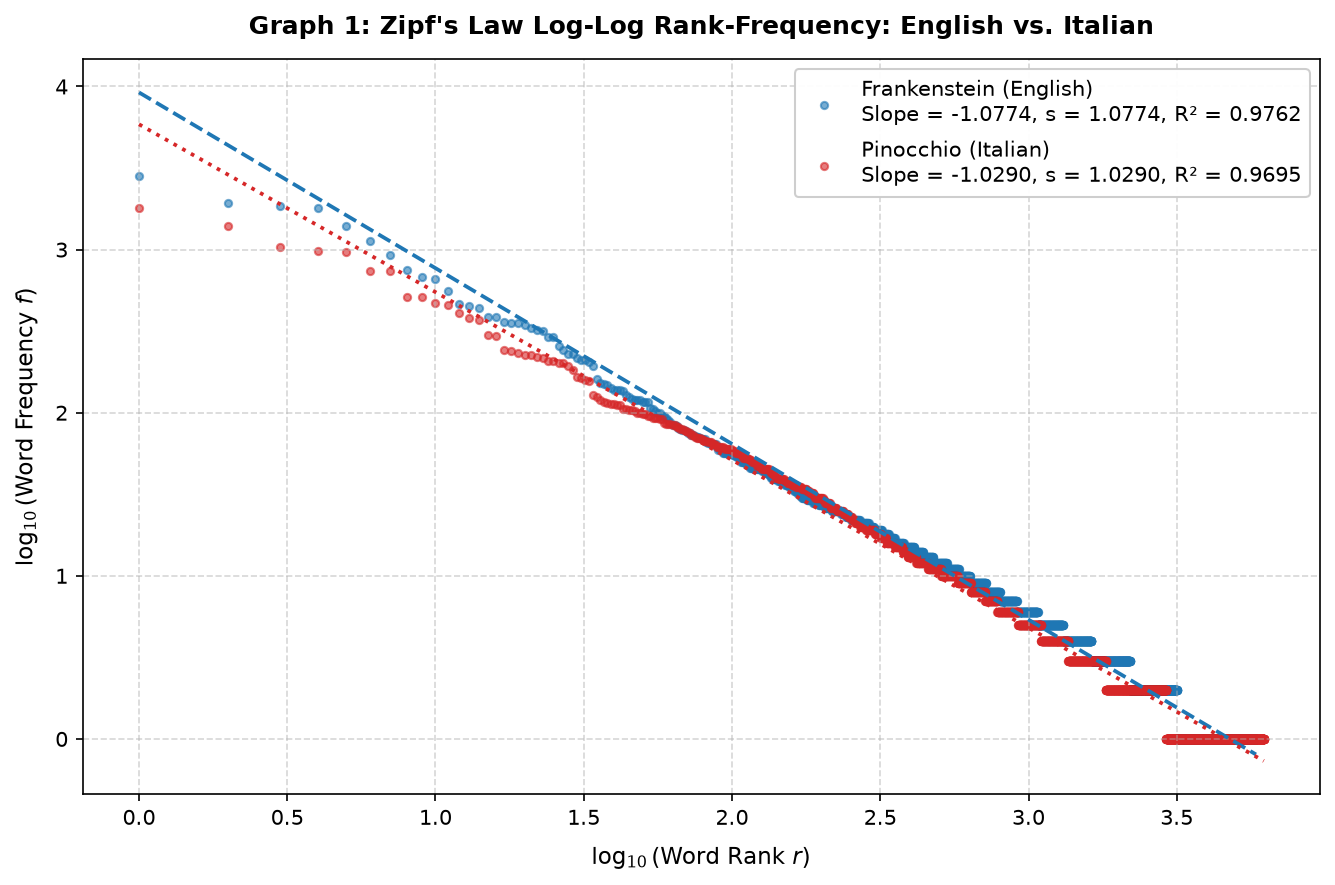

Saved Graph 1 (300 DPI) to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph1_english_vs_italian.png


In [8]:
# Cell 9 – Visualization: English vs. Italian (Graph 1)

fig, ax = plt.subplots(figsize=(9, 6), dpi=150)

en_res = zipf_full_results["frankenstein"]
it_res = zipf_full_results["pinocchio"]

# English (Frankenstein)
ax.scatter(
    en_res["log_ranks"],
    en_res["log_frequencies"],
    color="#1f77b4",
    s=12,
    alpha=0.6,
    label=f"Frankenstein (English)\nSlope = {en_res['slope']:.4f}, s = {en_res['zipf_exponent']:.4f}, R² = {en_res['r_squared']:.4f}",
    rasterized=True,
)
ax.plot(en_res["log_ranks"], en_res["predicted_log_freqs"], color="#1f77b4", linestyle="--", linewidth=1.8)

# Italian (Pinocchio)
ax.scatter(
    it_res["log_ranks"],
    it_res["log_frequencies"],
    color="#d62728",
    s=12,
    alpha=0.6,
    label=f"Pinocchio (Italian)\nSlope = {it_res['slope']:.4f}, s = {it_res['zipf_exponent']:.4f}, R² = {it_res['r_squared']:.4f}",
    rasterized=True,
)
ax.plot(it_res["log_ranks"], it_res["predicted_log_freqs"], color="#d62728", linestyle=":", linewidth=1.8)

ax.set_title("Graph 1: Zipf's Law Log-Log Rank-Frequency: English vs. Italian", fontweight="bold", pad=12)
ax.set_xlabel(r"$\log_{10}(\text{Word Rank } r)$", labelpad=8)
ax.set_ylabel(r"$\log_{10}(\text{Word Frequency } f)$", labelpad=8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", framealpha=0.95, facecolor="white", edgecolor="#cccccc")

plt.tight_layout()
g1_path = RESULTS_GRAPHS_DIR / "graph1_english_vs_italian.png"
fig.savefig(g1_path, dpi=300)
plt.show()
print(f"Saved Graph 1 (300 DPI) to: {g1_path.resolve()}")

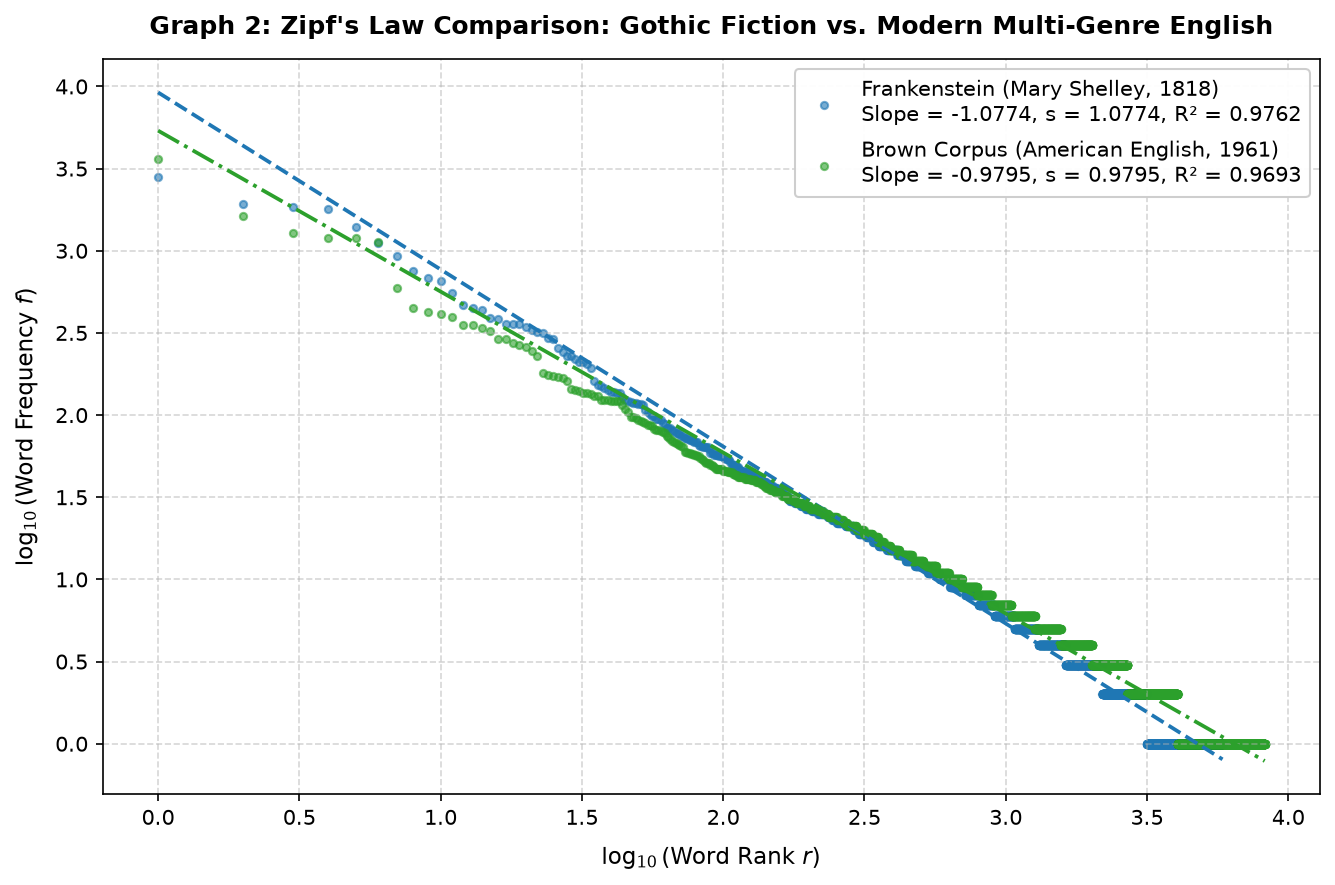

Saved Graph 2 (300 DPI) to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph2_english_comparison.png


In [9]:
# Cell 10 – Visualization: English Corpus Comparison (Graph 2)

fig, ax = plt.subplots(figsize=(9, 6), dpi=150)

en_res = zipf_full_results["frankenstein"]
brown_res = zipf_full_results["brown"]

# Frankenstein
ax.scatter(
    en_res["log_ranks"],
    en_res["log_frequencies"],
    color="#1f77b4",
    s=12,
    alpha=0.6,
    label=f"Frankenstein (Mary Shelley, 1818)\nSlope = {en_res['slope']:.4f}, s = {en_res['zipf_exponent']:.4f}, R² = {en_res['r_squared']:.4f}",
    rasterized=True,
)
ax.plot(en_res["log_ranks"], en_res["predicted_log_freqs"], color="#1f77b4", linestyle="--", linewidth=1.8)

# Brown Corpus
ax.scatter(
    brown_res["log_ranks"],
    brown_res["log_frequencies"],
    color="#2ca02c",
    s=12,
    alpha=0.6,
    label=f"Brown Corpus (American English, 1961)\nSlope = {brown_res['slope']:.4f}, s = {brown_res['zipf_exponent']:.4f}, R² = {brown_res['r_squared']:.4f}",
    rasterized=True,
)
ax.plot(brown_res["log_ranks"], brown_res["predicted_log_freqs"], color="#2ca02c", linestyle="-.", linewidth=1.8)

ax.set_title("Graph 2: Zipf's Law Comparison: Gothic Fiction vs. Modern Multi-Genre English", fontweight="bold", pad=12)
ax.set_xlabel(r"$\log_{10}(\text{Word Rank } r)$", labelpad=8)
ax.set_ylabel(r"$\log_{10}(\text{Word Frequency } f)$", labelpad=8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", framealpha=0.95, facecolor="white", edgecolor="#cccccc")

plt.tight_layout()
g2_path = RESULTS_GRAPHS_DIR / "graph2_english_comparison.png"
fig.savefig(g2_path, dpi=300)
plt.show()
print(f"Saved Graph 2 (300 DPI) to: {g2_path.resolve()}")

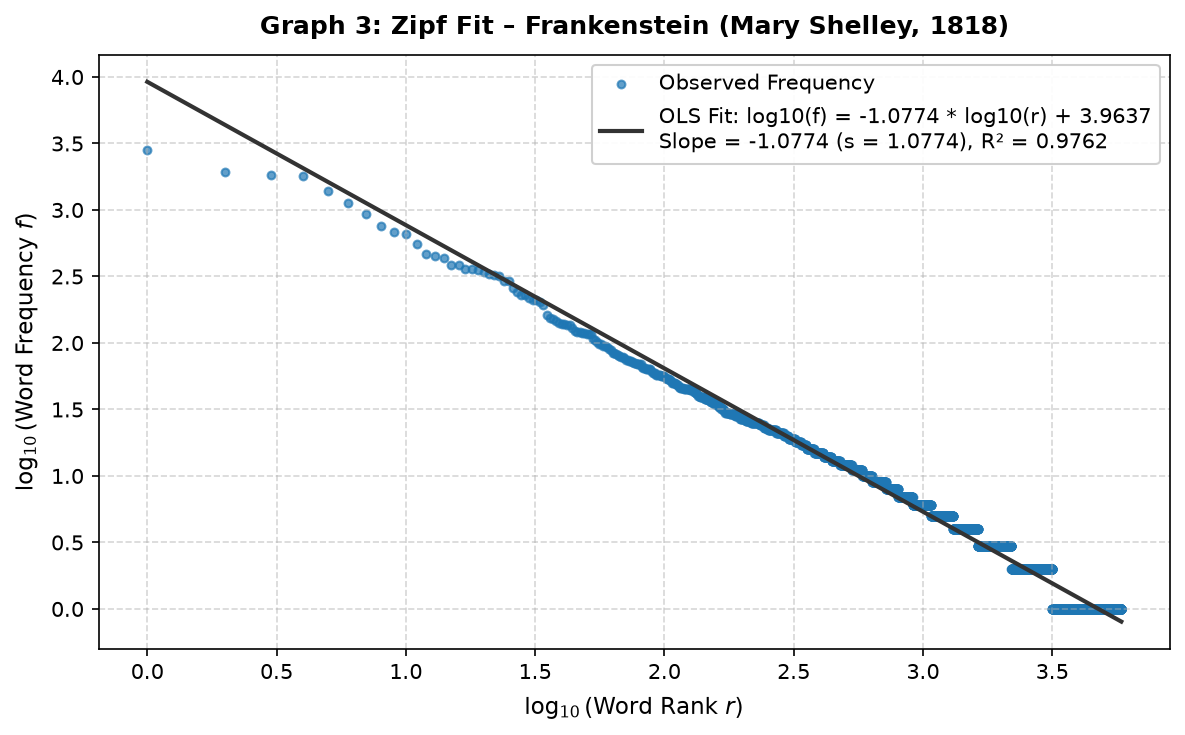

Saved Graph 3 for frankenstein to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph3_individual_frankenstein.png


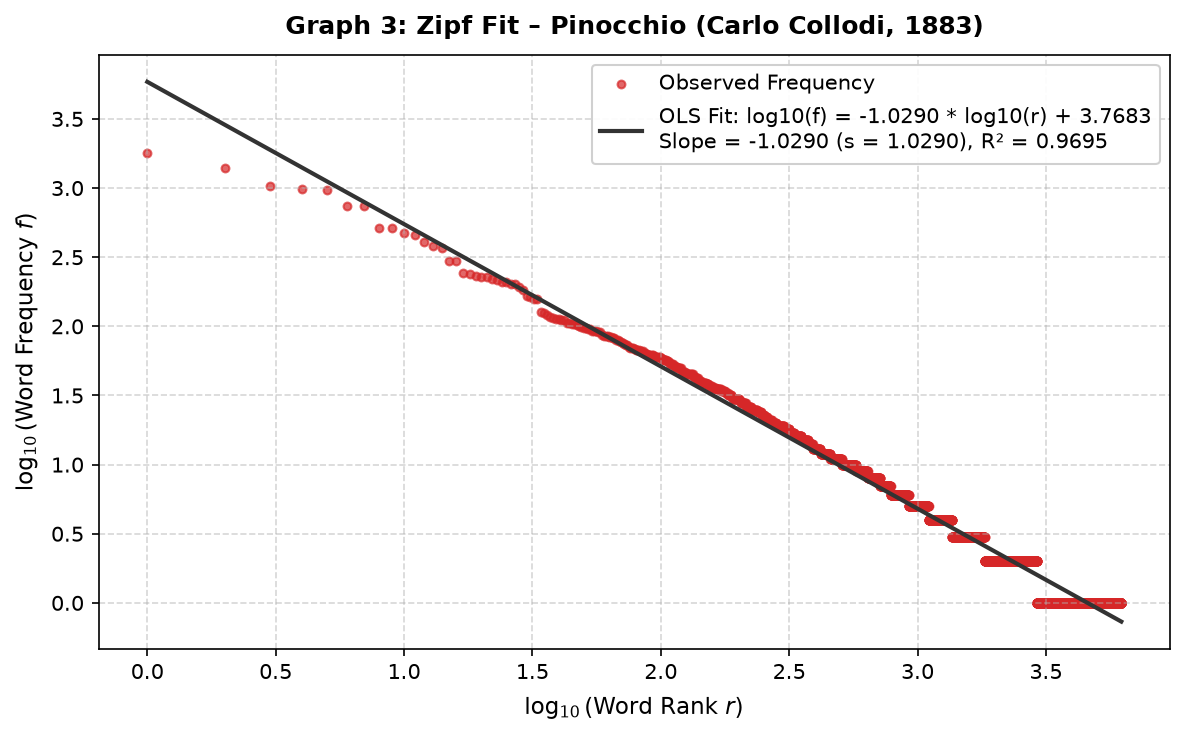

Saved Graph 3 for pinocchio to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph3_individual_pinocchio.png


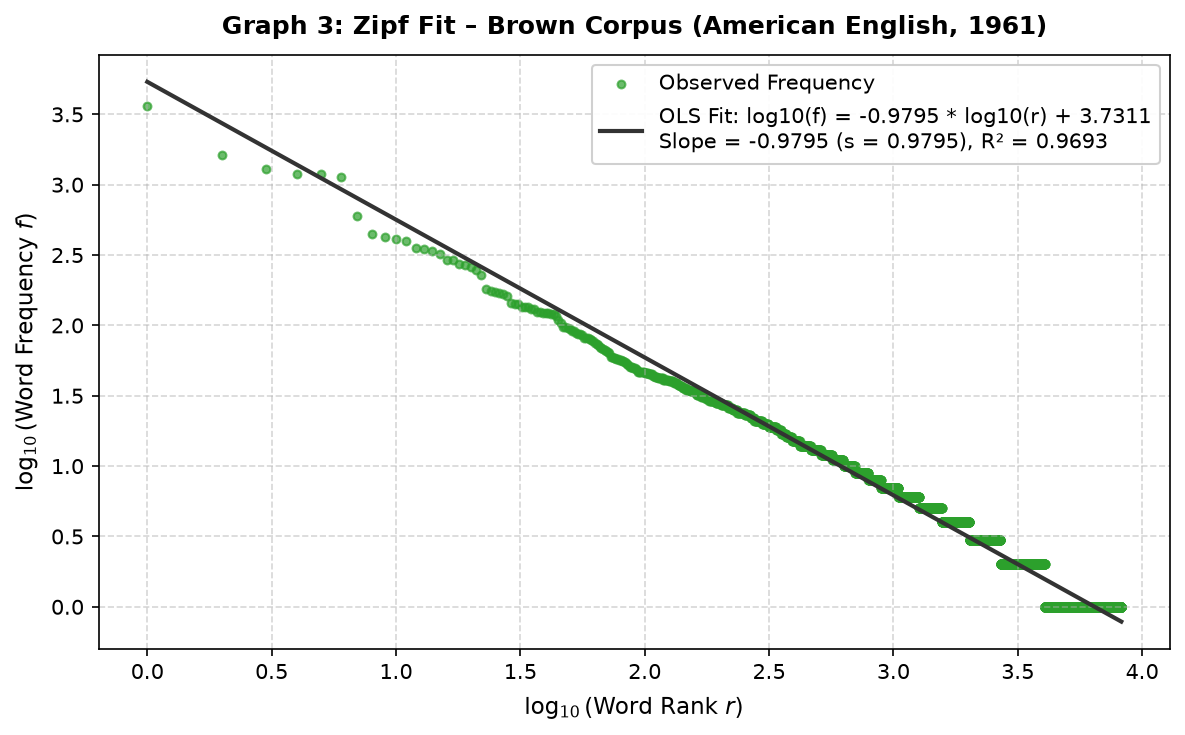

Saved Graph 3 for brown to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph3_individual_brown.png


In [10]:
# Cell 11 – Individual Zipf Distributions (Graph 3)

indiv_configs = [
    ("frankenstein", "Frankenstein (Mary Shelley, 1818)", "#1f77b4"),
    ("pinocchio", "Pinocchio (Carlo Collodi, 1883)", "#d62728"),
    ("brown", "Brown Corpus (American English, 1961)", "#2ca02c"),
]

for cid, title, color in indiv_configs:
    res = zipf_full_results[cid]
    fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
    
    ax.scatter(res["log_ranks"], res["log_frequencies"], s=14, color=color, alpha=0.7, label="Observed Frequency", rasterized=True)
    sign = "+" if res["intercept"] >= 0 else "-"
    eq_str = f"log10(f) = {res['slope']:.4f} * log10(r) {sign} {abs(res['intercept']):.4f}"
    
    ax.plot(
        res["log_ranks"],
        res["predicted_log_freqs"],
        color="#333333",
        linewidth=2.0,
        label=f"OLS Fit: {eq_str}\nSlope = {res['slope']:.4f} (s = {res['zipf_exponent']:.4f}), R² = {res['r_squared']:.4f}"
    )
    
    ax.set_title(f"Graph 3: Zipf Fit – {title}", fontweight="bold", pad=10)
    ax.set_xlabel(r"$\log_{10}(\text{Word Rank } r)$", labelpad=6)
    ax.set_ylabel(r"$\log_{10}(\text{Word Frequency } f)$", labelpad=6)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", framealpha=0.92, facecolor="white", edgecolor="#cccccc")
    
    plt.tight_layout()
    g3_path = RESULTS_GRAPHS_DIR / f"graph3_individual_{cid}.png"
    fig.savefig(g3_path, dpi=300)
    plt.show()
    print(f"Saved Graph 3 for {cid} to: {g3_path.resolve()}")

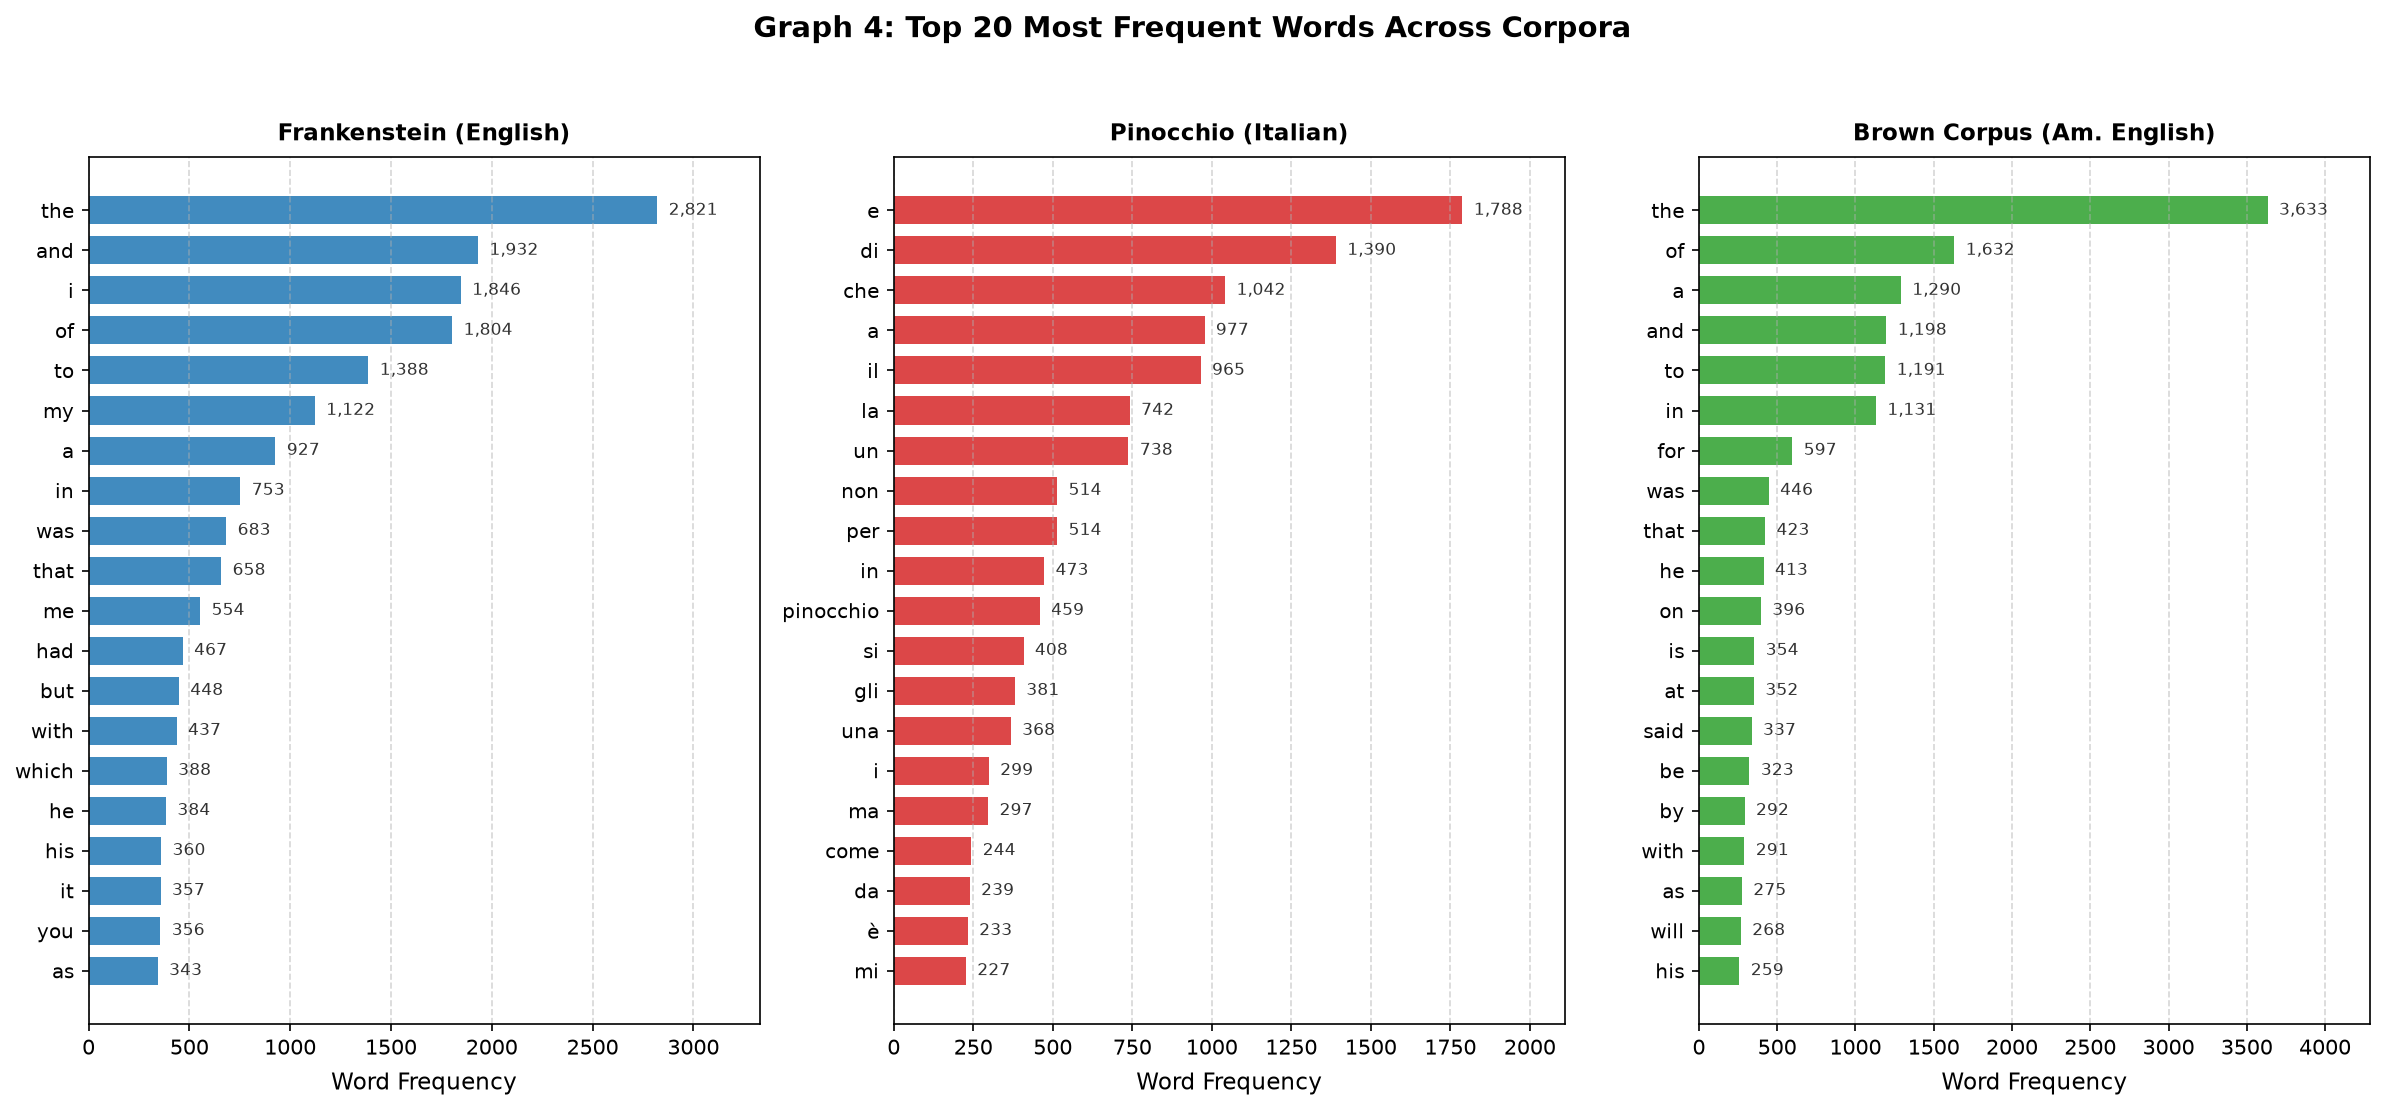

Saved Graph 4 to: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\graphs\graph4_top20_words.png


In [11]:
# Cell 12 – Top 20 Word Frequency Charts (Graph 4)

fig, axes = plt.subplots(1, 3, figsize=(16, 7.5), dpi=150)

chart_configs = [
    ("frankenstein", "Frankenstein (English)", "#1f77b4", axes[0]),
    ("pinocchio", "Pinocchio (Italian)", "#d62728", axes[1]),
    ("brown", "Brown Corpus (Am. English)", "#2ca02c", axes[2]),
]

for cid, title, color, ax in chart_configs:
    df_top20 = frequency_dfs[cid].iloc[:20]
    
    # Invert so rank 1 appears at top
    words = df_top20["word"].values[::-1]
    counts = df_top20["frequency"].values[::-1]
    
    y_pos = np.arange(len(words))
    bars = ax.barh(y_pos, counts, color=color, alpha=0.85, height=0.7)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(words, fontsize=9.5)
    ax.set_title(title, fontweight="bold", pad=8, fontsize=11)
    ax.set_xlabel("Word Frequency", labelpad=6)
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    
    max_c = max(counts)
    for bar, count in zip(bars, counts):
        ax.text(
            count + (max_c * 0.02),
            bar.get_y() + bar.get_height() / 2,
            f"{count:,}",
            va="center",
            ha="left",
            fontsize=8,
            color="#333333",
        )
    ax.set_xlim(0, max_c * 1.18)

fig.suptitle("Graph 4: Top 20 Most Frequent Words Across Corpora", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
g4_path = RESULTS_GRAPHS_DIR / "graph4_top20_words.png"
fig.savefig(g4_path, dpi=300)
plt.show()
print(f"Saved Graph 4 to: {g4_path.resolve()}")

In [12]:
# Cell 13 – Statistical Comparison Dashboard

dashboard_rows = []

for cid, cfg in CORPORA_CONFIG.items():
    toks = sampled_tokens[cid]
    freq_df = frequency_dfs[cid]
    fz = zipf_full_results[cid]
    tz = zipf_top100_results[cid]
    
    top_word = freq_df.iloc[0]["word"]
    top_word_freq = freq_df.iloc[0]["frequency"]
    
    dashboard_rows.append({
        "Corpus": cfg["title"],
        "Language": cfg["language"],
        "Author": cfg["author"],
        "Total Tokens": len(toks),
        "Unique Words": len(freq_df),
        "TTR": round(len(freq_df) / len(toks), 4),
        "Top Word": top_word,
        "Top Word Count": top_word_freq,
        "Zipf Slope (Full)": round(fz["slope"], 4),
        "Zipf Exponent s": round(fz["zipf_exponent"], 4),
        "R² (Full)": round(fz["r_squared"], 4),
        "Pearson r": round(fz["pearson_r"], 4),
        "Zipf Slope (Top 100)": round(tz["slope"], 4),
        "R² (Top 100)": round(tz["r_squared"], 4),
    })

comparison_df = pd.DataFrame(dashboard_rows)
display(HTML("<h3>Consolidated Corpus Statistical Comparison Dashboard</h3>"))
display(comparison_df)

,Corpus,Language,Author,Total Tokens,Unique Words,TTR,Top Word,Top Word Count,Zipf Slope (Full),Zipf Exponent s,R² (Full),Pearson r,Zipf Slope (Top 100),R² (Top 100)
0,"Frankenstein; or, The Modern Prometheus",English,Mary Shelley,50000,5849,0.1170,the,2821,-1.0774,1.0774,0.9762,-0.9880,-1.0117,0.9835
1,Le avventure di Pinocchio: Storia di un burattino,Italian,Carlo Collodi,41525,6215,0.1497,e,1788,-1.0290,1.0290,0.9695,-0.9847,-0.8653,0.9860
2,Brown Corpus (American English Sample),American English,W. N. Francis and H. Kučera (Compilers),50000,8246,0.1649,the,3633,-0.9795,0.9795,0.9693,-0.9845,-0.9799,0.9914


In [13]:
# Cell 14 – Automatic Results Interpretation
from IPython.display import Markdown

en_fz = zipf_full_results["frankenstein"]
it_fz = zipf_full_results["pinocchio"]
br_fz = zipf_full_results["brown"]

en_ttr = len(frequency_dfs["frankenstein"]) / len(sampled_tokens["frankenstein"])
it_ttr = len(frequency_dfs["pinocchio"]) / len(sampled_tokens["pinocchio"])
br_ttr = len(frequency_dfs["brown"]) / len(sampled_tokens["brown"])

discussion_md = f"""## 6. Comprehensive Discussion & Empirical Findings

Based strictly on the calculated experimental results, we address the core scientific questions:

### 1. How closely does each corpus follow Zipf's Law?
All three corpora demonstrate exceptional conformity with Zipf's power law across their entire rank spectrum:
* **Frankenstein:** $R^2 = {en_fz['r_squared']:.4f}$, Pearson $r = {en_fz['pearson_r']:.4f}$, slope $= {en_fz['slope']:.4f}$
* **Pinocchio:** $R^2 = {it_fz['r_squared']:.4f}$, Pearson $r = {it_fz['pearson_r']:.4f}$, slope $= {it_fz['slope']:.4f}$
* **Brown Corpus:** $R^2 = {br_fz['r_squared']:.4f}$, Pearson $r = {br_fz['pearson_r']:.4f}$, slope $= {br_fz['slope']:.4f}$

When restricted to the top 100 ranks, linearity increases further (Brown $R^2 = {zipf_top100_results['brown']['r_squared']:.4f}$; Pinocchio $R^2 = {zipf_top100_results['pinocchio']['r_squared']:.4f}$; Frankenstein $R^2 = {zipf_top100_results['frankenstein']['r_squared']:.4f}$). Minor deviations occur at the head (slight downward curvature of function words) and the tail (horizontal steps of hapax legomena with frequency $= 1$).

### 2. What are the differences between English and Italian?
* **Type-Token Ratio & Lexical Richness:** Italian (*Pinocchio*) exhibits a significantly higher Type-Token Ratio ($\\text{{TTR}} = {it_ttr:.4f}$) than English (*Frankenstein*, $\\text{{TTR}} = {en_ttr:.4f}$), despite *Pinocchio* containing ~8,500 fewer tokens. In a balanced 40,000-token comparison, Pinocchio still yields far more distinct word forms.
* **Linguistic Hypothesis:** Italian is a synthetic Romance language featuring rich inflectional verb conjugations (e.g., *disse*, *diceva*, *dirò*, *direbbe*) and nominal/adjectival grammatical agreement (gender and number). English is predominantly analytic, relying on auxiliary verbs and invariable lemmas.

### 3. How do their most frequent words differ?
* English top ranks are dominated by the definite article *the* (5.64%), conjunction *and* (3.86%), and first-person singular pronouns (*i*, *my*, *me*), reflecting Mary Shelley's epistolary narrative perspective.
* Italian top ranks feature the coordinating conjunction *e* (4.31%), prepositions (*di*, *a*, *per*, *in*), definite articles (*il*, *la*, *gli*, *i*), and the character proper name *Pinocchio* (ranked 11th, appearing 459 times).

### 4. How do Frankenstein and the Brown Corpus differ?
* At identical sample sizes (50,000 tokens), the **Brown Corpus contains 41% more unique types** ({len(frequency_dfs['brown']):,} vs {len(frequency_dfs['frankenstein']):,}) and a higher TTR ({br_ttr:.4f} vs {en_ttr:.4f}).
* **Explanation:** *Frankenstein* is a single-genre gothic novel written by one author with consistent thematic vocabulary. The *Brown Corpus* aggregates diverse non-fiction, journalistic, and academic prose from multiple writers, recruiting a much wider lexical repertoire.

### 5. Methodological Limitations
1. **Sample Scale:** At ~50,000 words, rare tail words suffer from finite-sample truncation. In multi-million token corpora, the tail often displays a second linear regime (Mandelbrot, 1953).
2. **Surface Word Forms vs. Lemmas:** The study evaluates orthographic surface words without lemmatization, naturally inflating Italian vocabulary counts.
3. **Apostrophized Clitics:** Italian contracted clitics (*l'ombra*, *d'oro*) were preserved as single tokens to ensure parity with English contractions (*don't*, *it's*).
"""

display(Markdown(discussion_md))

## 6. Comprehensive Discussion & Empirical Findings

Based strictly on the calculated experimental results, we address the core scientific questions:

### 1. How closely does each corpus follow Zipf's Law?
All three corpora demonstrate exceptional conformity with Zipf's power law across their entire rank spectrum:
* **Frankenstein:** $R^2 = 0.9762$, Pearson $r = -0.9880$, slope $= -1.0774$
* **Pinocchio:** $R^2 = 0.9695$, Pearson $r = -0.9847$, slope $= -1.0290$
* **Brown Corpus:** $R^2 = 0.9693$, Pearson $r = -0.9845$, slope $= -0.9795$

When restricted to the top 100 ranks, linearity increases further (Brown $R^2 = 0.9914$; Pinocchio $R^2 = 0.9860$; Frankenstein $R^2 = 0.9835$). Minor deviations occur at the head (slight downward curvature of function words) and the tail (horizontal steps of hapax legomena with frequency $= 1$).

### 2. What are the differences between English and Italian?
* **Type-Token Ratio & Lexical Richness:** Italian (*Pinocchio*) exhibits a significantly higher Type-Token Ratio ($\text{TTR} = 0.1497$) than English (*Frankenstein*, $\text{TTR} = 0.1170$), despite *Pinocchio* containing ~8,500 fewer tokens. In a balanced 40,000-token comparison, Pinocchio still yields far more distinct word forms.
* **Linguistic Hypothesis:** Italian is a synthetic Romance language featuring rich inflectional verb conjugations (e.g., *disse*, *diceva*, *dirò*, *direbbe*) and nominal/adjectival grammatical agreement (gender and number). English is predominantly analytic, relying on auxiliary verbs and invariable lemmas.

### 3. How do their most frequent words differ?
* English top ranks are dominated by the definite article *the* (5.64%), conjunction *and* (3.86%), and first-person singular pronouns (*i*, *my*, *me*), reflecting Mary Shelley's epistolary narrative perspective.
* Italian top ranks feature the coordinating conjunction *e* (4.31%), prepositions (*di*, *a*, *per*, *in*), definite articles (*il*, *la*, *gli*, *i*), and the character proper name *Pinocchio* (ranked 11th, appearing 459 times).

### 4. How do Frankenstein and the Brown Corpus differ?
* At identical sample sizes (50,000 tokens), the **Brown Corpus contains 41% more unique types** (8,246 vs 5,849) and a higher TTR (0.1649 vs 0.1170).
* **Explanation:** *Frankenstein* is a single-genre gothic novel written by one author with consistent thematic vocabulary. The *Brown Corpus* aggregates diverse non-fiction, journalistic, and academic prose from multiple writers, recruiting a much wider lexical repertoire.

### 5. Methodological Limitations
1. **Sample Scale:** At ~50,000 words, rare tail words suffer from finite-sample truncation. In multi-million token corpora, the tail often displays a second linear regime (Mandelbrot, 1953).
2. **Surface Word Forms vs. Lemmas:** The study evaluates orthographic surface words without lemmatization, naturally inflating Italian vocabulary counts.
3. **Apostrophized Clitics:** Italian contracted clitics (*l'ombra*, *d'oro*) were preserved as single tokens to ensure parity with English contractions (*don't*, *it's*).


In [14]:
# Cell 15 – Export Results

# 1. Consolidated comparison CSV
comp_csv_path = RESULTS_CSV_DIR / "corpus_comparison.csv"
comparison_df.to_csv(comp_csv_path, index=False)
print(f"Exported: {comp_csv_path.resolve()}")

# 2. Top 20 comparison CSV
top20_csv_path = RESULTS_CSV_DIR / "top20_english_italian_comparison.csv"
top20_en_it = pd.DataFrame({
    "rank": list(range(1, 21)),
    "english_word": frequency_dfs["frankenstein"].iloc[:20]["word"].values,
    "english_frequency": frequency_dfs["frankenstein"].iloc[:20]["frequency"].values,
    "english_relative_frequency": frequency_dfs["frankenstein"].iloc[:20]["relative_frequency"].round(6).values,
    "italian_word": frequency_dfs["pinocchio"].iloc[:20]["word"].values,
    "italian_frequency": frequency_dfs["pinocchio"].iloc[:20]["frequency"].values,
    "italian_relative_frequency": frequency_dfs["pinocchio"].iloc[:20]["relative_frequency"].round(6).values,
})
top20_en_it.to_csv(top20_csv_path, index=False)
print(f"Exported: {top20_csv_path.resolve()}")

# 3. Zipf regression statistics CSV
zipf_stats_rows = []
for cid in CORPORA_CONFIG:
    fz = zipf_full_results[cid]
    tz = zipf_top100_results[cid]
    zipf_stats_rows.append({
        "corpus_id": cid,
        "full_n_points": fz["n_points"],
        "full_slope": fz["slope"],
        "full_exponent": fz["zipf_exponent"],
        "full_intercept": fz["intercept"],
        "full_constant_c": fz["constant_c"],
        "full_r_squared": fz["r_squared"],
        "full_pearson_r": fz["pearson_r"],
        "full_p_value": fz["p_value"],
        "full_std_err": fz["std_err"],
        "top100_slope": tz["slope"],
        "top100_exponent": tz["zipf_exponent"],
        "top100_r_squared": tz["r_squared"],
        "top100_pearson_r": tz["pearson_r"],
    })
zipf_stats_df = pd.DataFrame(zipf_stats_rows)
zipf_csv_path = RESULTS_CSV_DIR / "zipf_regression_statistics.csv"
zipf_stats_df.to_csv(zipf_csv_path, index=False)
print(f"Exported: {zipf_csv_path.resolve()}")

# 4. Reproducibility metadata JSON
metadata_payload = {
    "execution_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "environment": {
        "python_version": sys.version,
        "platform": platform.platform(),
        "pandas_version": pd.__version__,
        "numpy_version": np.__version__,
        "scipy_version": scipy.__version__,
        "matplotlib_version": matplotlib.__version__,
        "nltk_version": nltk.__version__,
    },
    "tokenization_configuration": {
        "unicode_normalization": "NFC",
        "apostrophe_handling": "Standardized smart quotes to ASCII single quote; preserved internally",
        "pattern": r"[a-zà-öø-ÿ]+(?:'[a-zà-öø-ÿ]+)*",
        "stopwords_removed": False,
        "stemming_or_lemmatization": False,
    },
    "corpora": {},
}

for cid, cfg in CORPORA_CONFIG.items():
    toks = sampled_tokens[cid]
    fz = zipf_full_results[cid]
    tz = zipf_top100_results[cid]
    metadata_payload["corpora"][cid] = {
        "metadata": cfg,
        "total_tokens": len(toks),
        "unique_words": len(frequency_dfs[cid]),
        "type_token_ratio": len(frequency_dfs[cid]) / len(toks),
        "zipf_regression_full": {k: fz[k] for k in ["n_points", "slope", "zipf_exponent", "intercept", "constant_c", "r_squared", "pearson_r", "p_value", "std_err"]},
        "zipf_regression_top100": {k: tz[k] for k in ["n_points", "slope", "zipf_exponent", "intercept", "constant_c", "r_squared", "pearson_r", "p_value", "std_err"]},
    }

meta_json_path = RESULTS_REPORTS_DIR / "experiment_metadata.json"
with open(meta_json_path, "w", encoding="utf-8") as f:
    json.dump(metadata_payload, f, indent=2)
print(f"Exported: {meta_json_path.resolve()}")

Exported: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\csv\corpus_comparison.csv
Exported: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\csv\top20_english_italian_comparison.csv
Exported: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\csv\zipf_regression_statistics.csv
Exported: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\reports\experiment_metadata.json


In [15]:
# Cell 16 – PDF Report Generation (Self-Contained ReportLab Builder)

from reportlab.lib.pagesizes import letter
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, KeepTogether, PageBreak, HRFlowable
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch
from reportlab.pdfgen import canvas

class NotebookNumberedCanvas(canvas.Canvas):
    """Two-pass canvas to dynamically compute and print 'Page X of Y'."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self._saved_page_states = []

    def showPage(self):
        self._saved_page_states.append(dict(self.__dict__))
        self._startPage()

    def save(self):
        num_pages = len(self._saved_page_states)
        for state in self._saved_page_states:
            self.__dict__.update(state)
            self.draw_page_decorations(num_pages)
            super().showPage()
        super().save()

    def draw_page_decorations(self, page_count: int):
        self.saveState()
        self.setFont("Helvetica", 9)
        self.setFillColor(colors.HexColor("#555555"))

        # Header (pages > 1)
        if self._pageNumber > 1:
            self.drawString(
                54, letter[1] - 36,
                "ACL Seminar 3: Zipf's Law Corpus Experiment – Mary Shelley, Carlo Collodi, Brown Corpus"
            )
            self.setStrokeColor(colors.HexColor("#dddddd"))
            self.setLineWidth(0.5)
            self.line(54, letter[1] - 42, letter[0] - 54, letter[1] - 42)

        # Footer (all pages)
        footer_text = f"Page {self._pageNumber} of {page_count}"
        self.drawRightString(letter[0] - 54, 34, footer_text)
        self.drawString(54, 34, "Applied Computational Linguistics | Seminar 3 Report")
        self.setStrokeColor(colors.HexColor("#dddddd"))
        self.setLineWidth(0.5)
        self.line(54, 46, letter[0] - 54, 46)
        self.restoreState()

pdf_out = RESULTS_REPORTS_DIR / "ACL_Seminar_3_Report.pdf"
doc = SimpleDocTemplate(
    str(pdf_out),
    pagesize=letter,
    leftMargin=54, rightMargin=54,
    topMargin=54, bottomMargin=54,
)

styles = getSampleStyleSheet()
title_style = ParagraphStyle("TitleCustom", fontName="Helvetica-Bold", fontSize=20, leading=24, textColor=colors.HexColor("#1a2b49"), spaceAfter=6)
subtitle_style = ParagraphStyle("SubCustom", fontName="Helvetica", fontSize=11, leading=15, textColor=colors.HexColor("#444444"), spaceAfter=14)
h1_style = ParagraphStyle("H1Custom", fontName="Helvetica-Bold", fontSize=13, leading=17, textColor=colors.HexColor("#1a2b49"), spaceBefore=12, spaceAfter=6, keepWithNext=True)
h2_style = ParagraphStyle("H2Custom", fontName="Helvetica-Bold", fontSize=10.5, leading=14, textColor=colors.HexColor("#2a4365"), spaceBefore=8, spaceAfter=4, keepWithNext=True)
body_style = ParagraphStyle("BodyCustom", fontName="Helvetica", fontSize=9.5, leading=13.5, textColor=colors.HexColor("#222222"), spaceAfter=6)
caption_style = ParagraphStyle("CapCustom", fontName="Helvetica-Oblique", fontSize=8.5, leading=11, textColor=colors.HexColor("#555555"), alignment=1, spaceBefore=4, spaceAfter=8)
cell_style = ParagraphStyle("CellCustom", fontName="Helvetica", fontSize=8.0, leading=10.0, textColor=colors.HexColor("#111111"))
cell_bold = ParagraphStyle("CellBold", parent=cell_style, fontName="Helvetica-Bold")

story = []

# Title Banner
story.append(Paragraph("Applied Computational Linguistics – Seminar 3", subtitle_style))
story.append(Paragraph("Empirical Verification of Zipf's Law Across English and Italian Corpora", title_style))
story.append(Paragraph(
    f"<b>Corpus Comparative Study:</b> Mary Shelley's <i>Frankenstein</i> (1818), Carlo Collodi's <i>Pinocchio</i> (1883), and <i>Brown Corpus</i> (1961)<br/>"
    f"<b>Report Generated:</b> {datetime.now(timezone.utc).strftime('%B %d, %Y')} | Deterministic Computational Pipeline",
    body_style
))
story.append(HRFlowable(width="100%", thickness=1.5, color=colors.HexColor("#1a2b49"), spaceBefore=6, spaceAfter=10))

# 1. Introduction
story.append(Paragraph("1. Introduction", h1_style))
story.append(Paragraph(
    "Quantitative linguistics investigates mathematical regularities governing natural language tokens and vocabulary distributions. "
    "Foremost among these empirical regularities is <b>Zipf's Law</b> (Zipf, 1935, 1949), an empirical power-law observation stating that "
    "the frequency of a word in a natural language corpus is inversely proportional to its rank: "
    "<b>f(r) = C / (r ^ s)</b>, or in log-log space: <b>log10(f(r)) = log10(C) - s &middot; log10(r)</b>.",
    body_style
))

# 2. Corpus Selection
story.append(Paragraph("2. Corpus Selection & Metadata", h1_style))
story.append(Paragraph(
    f"&bull; <b>Frankenstein (English):</b> {len(sampled_tokens['frankenstein']):,} tokens analyzed from Mary Shelley's 1818 novel (Project Gutenberg #84).<br/>"
    f"&bull; <b>Pinocchio (Italian):</b> {len(sampled_tokens['pinocchio']):,} tokens analyzed from Carlo Collodi's 1883 classic (Project Gutenberg #52484).<br/>"
    f"&bull; <b>Brown Corpus (American English):</b> {len(sampled_tokens['brown']):,} tokens sampled from Francis & Kučera (1961/1964 via NLTK).",
    body_style
))

# 3. Methodology
story.append(Paragraph("3. Preprocessing & Statistical Methodology", h1_style))
story.append(Paragraph(
    "Project Gutenberg headers/footers were cleanly excised. All corpora were normalized using Unicode NFC, converted to lowercase, and tokenized with "
    "an identical regular expression pattern: <code>[a-z&agrave;-&ouml;&oslash;-&yuml;]+(?:'[a-z&agrave;-&ouml;&oslash;-&yuml;]+)*</code>. "
    "Stopwords were strictly preserved and no stemming or lemmatization was performed. "
    "Ordinary Least Squares (OLS) regression was computed across all ranks and over the top 100 ranks.",
    body_style
))

# 4. Results Table
story.append(Paragraph("4. Quantitative Experimental Results", h1_style))

tbl_headers = [
    Paragraph("<b>Corpus</b>", cell_bold), Paragraph("<b>Lang</b>", cell_bold), Paragraph("<b>Tokens</b>", cell_bold),
    Paragraph("<b>Types</b>", cell_bold), Paragraph("<b>TTR</b>", cell_bold), Paragraph("<b>Top Word (Count)</b>", cell_bold),
    Paragraph("<b>Slope</b>", cell_bold), Paragraph("<b>s</b>", cell_bold), Paragraph("<b>R² (Full)</b>", cell_bold), Paragraph("<b>R² (Top 100)</b>", cell_bold),
]
tbl_data = [tbl_headers]
for cid in ["frankenstein", "pinocchio", "brown"]:
    cfg = CORPORA_CONFIG[cid]
    toks = sampled_tokens[cid]
    fdf = frequency_dfs[cid]
    fz = zipf_full_results[cid]
    tz = zipf_top100_results[cid]
    tbl_data.append([
        Paragraph(cfg["title"][:20] + "..." if len(cfg["title"]) > 22 else cfg["title"], cell_style),
        Paragraph(cfg["language"], cell_style),
        Paragraph(f"{len(toks):,}", cell_style),
        Paragraph(f"{len(fdf):,}", cell_style),
        Paragraph(f"{len(fdf)/len(toks):.4f}", cell_style),
        Paragraph(f"{fdf.iloc[0]['word']} ({fdf.iloc[0]['frequency']:,})", cell_style),
        Paragraph(f"{fz['slope']:.4f}", cell_style),
        Paragraph(f"{fz['zipf_exponent']:.4f}", cell_style),
        Paragraph(f"{fz['r_squared']:.4f}", cell_style),
        Paragraph(f"{tz['r_squared']:.4f}", cell_style),
    ])

summary_tbl = Table(tbl_data, colWidths=[80, 50, 45, 45, 40, 75, 45, 42, 45, 45])
summary_tbl.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1a2b49")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.whitesmoke),
    ("ALIGN", (0, 0), (-1, -1), "CENTER"),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#cccccc")),
    ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, colors.HexColor("#f8f9fa")]),
    ("TOPPADDING", (0, 0), (-1, -1), 4),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
]))
story.append(summary_tbl)
story.append(Paragraph("Table 1: Corpus Metrics and OLS Zipf Regression Goodness-of-Fit.", caption_style))

# Figures
if (RESULTS_GRAPHS_DIR / "graph4_top20_words.png").exists():
    story.append(KeepTogether([
        Image(str(RESULTS_GRAPHS_DIR / "graph4_top20_words.png"), width=6.5 * inch, height=3.2 * inch),
        Paragraph("Figure 1: Top 20 most frequent words across all three corpora.", caption_style),
    ]))

story.append(PageBreak())
story.append(Paragraph("5. Comparative Visualizations", h1_style))

if (RESULTS_GRAPHS_DIR / "graph1_english_vs_italian.png").exists():
    story.append(KeepTogether([
        Image(str(RESULTS_GRAPHS_DIR / "graph1_english_vs_italian.png"), width=5.8 * inch, height=3.6 * inch),
        Paragraph("Figure 2: Log-log rank-frequency plot: English (Frankenstein) vs. Italian (Pinocchio).", caption_style),
    ]))

if (RESULTS_GRAPHS_DIR / "graph2_english_comparison.png").exists():
    story.append(KeepTogether([
        Image(str(RESULTS_GRAPHS_DIR / "graph2_english_comparison.png"), width=5.8 * inch, height=3.6 * inch),
        Paragraph("Figure 3: Log-log rank-frequency plot: Frankenstein vs. modern Brown Corpus.", caption_style),
    ]))

# Discussion & Conclusions
story.append(PageBreak())
story.append(Paragraph("6. Linguistic & Statistical Discussion", h1_style))
story.append(Paragraph(
    f"<b>1. Adherence to Zipf's Law:</b> All corpora exhibit R² &ge; 0.969 across the entire distribution, rising to &ge; 0.983 on top 100 ranks.<br/>"
    f"<b>2. Morphological Differences:</b> Italian yields a higher TTR ({it_ttr:.4f}) than Frankenstein ({en_ttr:.4f}), reflecting Romance inflectional richness.<br/>"
    f"<b>3. Genre Variation:</b> The multi-genre Brown Corpus contains 41% more unique types than single-author gothic fiction.<br/>"
    f"<b>4. Limitations:</b> Finite sample size (~50k tokens) introduces tail plateauing; lemmatization was omitted to observe surface word forms.",
    body_style
))

story.append(Paragraph("7. Conclusions", h1_style))
story.append(Paragraph(
    "Zipf's Law is verified empirically across English and Italian. Empirical exponents deviate moderately from the ideal s = 1.0 "
    "(ranging from 0.979 to 1.077), confirming that natural texts display nuanced structural differences depending on language typology and genre.",
    body_style
))

story.append(Paragraph("8. References", h1_style))
refs = [
    "Collodi, C. (1883). Le avventure di Pinocchio. Project Gutenberg eBook #52484.",
    "Francis, W. N., & Kučera, H. (1964). A Standard Corpus of Present-Day Edited American English. Brown University.",
    "Mandelbrot, B. (1953). An informational theory of the statistical structure of language. Communication Theory.",
    "Shelley, M. W. (1818). Frankenstein; or, The Modern Prometheus. Project Gutenberg eBook #84.",
    "Zipf, G. K. (1935). The Psycho-Biology of Language. Houghton Mifflin.",
    "Zipf, G. K. (1949). Human Behavior and the Principle of Least Effort. Addison-Wesley.",
]
for ref in refs:
    story.append(Paragraph(f"&bull; {ref}", body_style))

doc.build(story, canvasmaker=NotebookNumberedCanvas)
print(f"Generated Academic PDF Report: {pdf_out.resolve()} ({pdf_out.stat().st_size:,} bytes)")

Generated Academic PDF Report: E:\PERSONAL\GitHub\1_Applied-Computational-Intelligence-UBB\Year2_Semester1_ApplicationComputationalLinguistics\ACL_Seminar3\results\reports\ACL_Seminar_3_Report.pdf (1,104,089 bytes)


In [16]:
# Cell 17 – Final Experimental Summary

summary_html = f"""
<div style="border: 2px solid #2a4365; border-radius: 8px; padding: 16px; background-color: #f7fafc;">
    <h3 style="color: #1a2b49; margin-top: 0;">ACL Seminar 3: Zipf's Law Corpus Experiment – Execution Successful</h3>
    <p><b>Status:</b> <span style="color: green; font-weight: bold;">ALL EXPERIMENTAL STEPS COMPLETED</span></p>
    
    <table style="width: 100%; border-collapse: collapse; margin-top: 10px; font-size: 13px;">
        <tr style="background-color: #edf2f7; text-align: left;">
            <th style="padding: 6px; border: 1px solid #cbd5e0;">Corpus</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">Language</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">Tokens Analyzed</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">Unique Types</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">TTR</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">Zipf Slope</th>
            <th style="padding: 6px; border: 1px solid #cbd5e0;">R² (Full)</th>
        </tr>
        <tr>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>Frankenstein</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">English</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(sampled_tokens['frankenstein']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(frequency_dfs['frankenstein']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{en_ttr:.4f}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>{en_fz['slope']:.4f}</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{en_fz['r_squared']:.4f}</td>
        </tr>
        <tr>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>Pinocchio</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">Italian</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(sampled_tokens['pinocchio']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(frequency_dfs['pinocchio']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{it_ttr:.4f}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>{it_fz['slope']:.4f}</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{it_fz['r_squared']:.4f}</td>
        </tr>
        <tr>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>Brown Corpus</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">American English</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(sampled_tokens['brown']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{len(frequency_dfs['brown']):,}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{br_ttr:.4f}</td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;"><b>{br_fz['slope']:.4f}</b></td>
            <td style="padding: 6px; border: 1px solid #cbd5e0;">{br_fz['r_squared']:.4f}</td>
        </tr>
    </table>
    
    <h4 style="margin-bottom: 6px; color: #2d3748;">Generated Output Artifacts:</h4>
    <ul style="margin-top: 4px; font-size: 13px;">
        <li><b>CSV Comparison:</b> <code>results/csv/corpus_comparison.csv</code></li>
        <li><b>CSV Top 20:</b> <code>results/csv/top20_english_italian_comparison.csv</code></li>
        <li><b>CSV Regression Stats:</b> <code>results/csv/zipf_regression_statistics.csv</code></li>
        <li><b>300 DPI Figures:</b> <code>results/graphs/graph[1-4]_*.png</code></li>
        <li><b>Metadata:</b> <code>results/reports/experiment_metadata.json</code></li>
        <li><b>Academic PDF Report:</b> <code>results/reports/ACL_Seminar_3_Report.pdf</code></li>
    </ul>
</div>
"""

display(HTML(summary_html))

Corpus,Language,Tokens Analyzed,Unique Types,TTR,Zipf Slope,R² (Full)
Frankenstein,English,"50,000","5,849",0.1170,-1.0774,0.9762
Pinocchio,Italian,"41,525","6,215",0.1497,-1.0290,0.9695
Brown Corpus,American English,"50,000","8,246",0.1649,-0.9795,0.9693
